In [1]:
%pip install -q tensorflow tensorflow-datasets matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)
print("TensorFlow Datasets version:", tfds.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
TensorFlow Datasets version: 4.9.10
GPU devices: []


In [5]:
(ds_train, ds_val, ds_test), ds_info = tfds.load(
    "tf_flowers",
    split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
    as_supervised=True,
    with_info=True
)

class_names = ds_info.features["label"].names
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)
print("Training examples:", ds_info.splits["train"].num_examples * 0.70)
print("Dataset loaded.")

Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Number of classes: 5
Training examples: 2569.0
Dataset loaded.


In [6]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def prepare_image(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    label = tf.one_hot(label, depth=num_classes)
    return image, label

train_ds = (
    ds_train
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
val_ds = (
    ds_val
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
test_ds = (
    ds_test
    .map(prepare_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Image preprocessing completed.")

Image preprocessing completed.


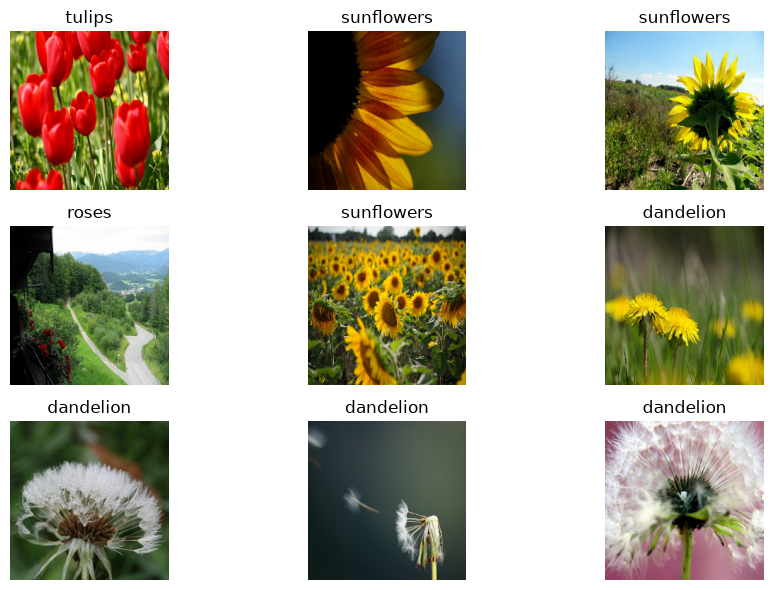

In [9]:
# Display 9 images from the raw dataset
import tensorflow as tf
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for images, labels in ds_train.map(
    lambda image, label: (
        tf.image.resize(image, (224, 224)),
        label
    )
).batch(9).take(1):

    for i in range(len(images)):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)

print("VGG16 loaded.")
print("Base model output shape:", base_model.output_shape)

VGG16 loaded.
Base model output shape: (None, 4, 4, 512)


In [12]:
base_model.trainable = False
print("Base model trainable:", base_model.trainable)

Base model trainable: False


In [13]:
inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)           │ (None, 150, 150, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 4, 4, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │          16,448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 5)                   │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,862,789 (56.70 MB)

 Trainable params: 148,101 (578.52 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [14]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 250s 3s/step - accuracy: 0.5983 - loss: 1.9037 - val_accuracy: 0.7042 - val_loss: 0.8027 - learning_rate: 0.0010
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 244s 3s/step - accuracy: 0.7575 - loss: 0.7186 - val_accuracy: 0.7967 - val_loss: 0.5796 - learning_rate: 0.0010
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 266s 3s/step - accuracy: 0.8206 - loss: 0.5040 - val_accuracy: 0.8185 - val_loss: 0.5450 - learning_rate: 0.0010
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 276s 3s/step - accuracy: 0.8540 - loss: 0.4226 - val_accuracy: 0.8167 - val_loss: 0.5339 - learning_rate: 0.0010
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 236s 3s/step - accuracy: 0.8809 - loss: 0.3268 - val_accuracy: 0.8403 - val_loss: 0.5120 - learning_rate: 0.0010
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 381s 5s/step - accuracy: 0.9085 - loss: 0.2573 - val_accuracy: 0.8421 - val_loss: 0.4928 - learning_rate: 0.0010
Epoch 7/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 242s 3s/step - accuracy: 0.9221 - loss: 0.2159 - val_acc

In [15]:
print("Training epochs completed:", len(history.history["loss"]))
print("Best validation accuracy:", max(history.history["val_accuracy"]))
print("Best validation loss:", min(history.history["val_loss"]))
print("Final training accuracy:", history.history["accuracy"][-1])

Training epochs completed: 11
Best validation accuracy: 0.8638838529586792
Best validation loss: 0.4744656980037689
Final training accuracy: 0.9645776748657227


In [16]:
print("Epochs recorded:", len(history.history["loss"]))

print("Best epoch:",
      history.history["val_loss"].index(
          min(history.history["val_loss"])
      ) + 1)

print("Early stopping patience:",
      callbacks[0].patience)

print("Restore best weights:",
      callbacks[0].restore_best_weights)

Epochs recorded: 11
Best epoch: 7
Early stopping patience: 4
Restore best weights: True


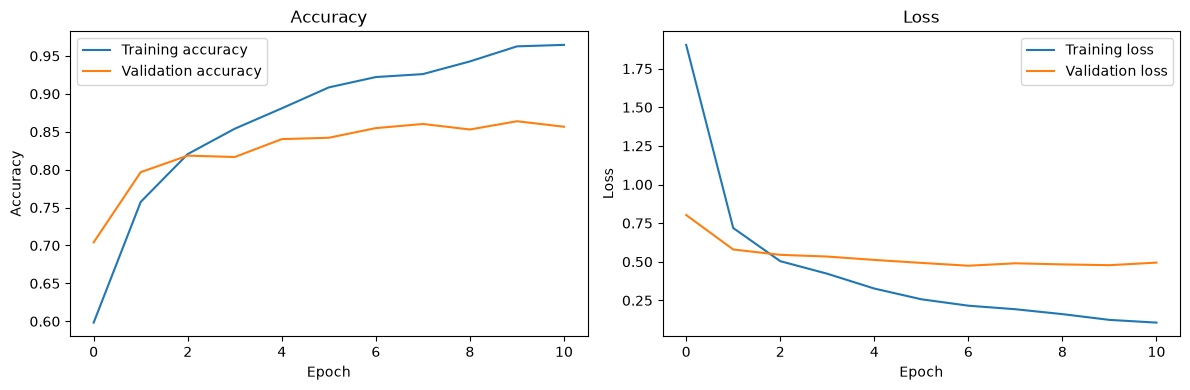

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

In [18]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy (%): {test_accuracy * 100:.2f}%")

18/18 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.8436 - loss: 0.5348
Test loss: 0.5348
Test accuracy: 0.8436
Test accuracy (%): 84.36%


In [19]:
y_true = []
y_pred = []

for images, labels in test_ds:
    probabilities = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(probabilities, axis=1))

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

   dandelion       0.90      0.87      0.88       112
       daisy       0.88      0.83      0.85        95
      tulips       0.84      0.80      0.82       134
  sunflowers       0.79      0.92      0.85       102
       roses       0.83      0.81      0.82       107

    accuracy                           0.84       550
   macro avg       0.85      0.85      0.84       550
weighted avg       0.85      0.84      0.84       550



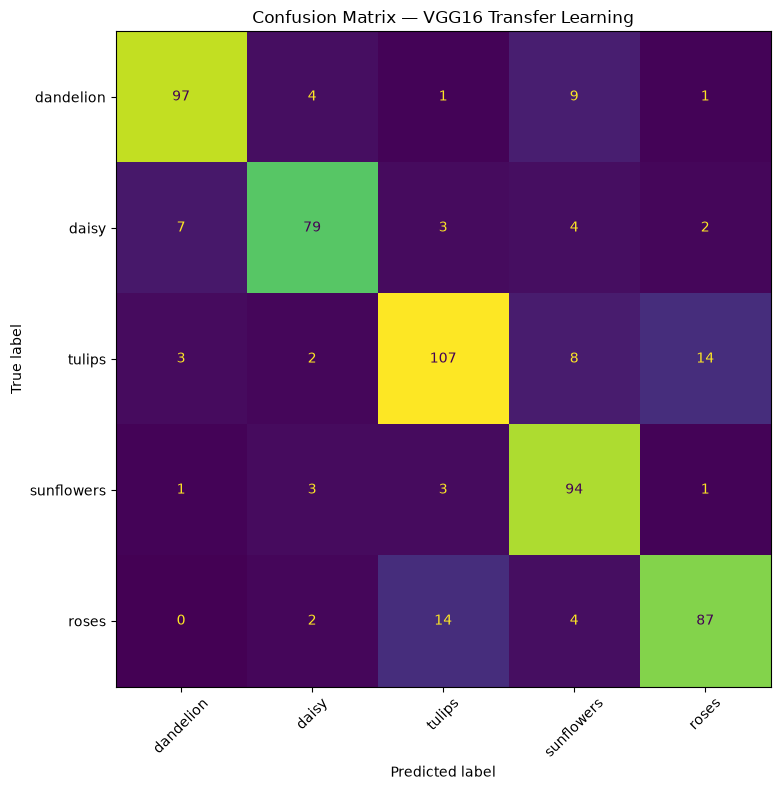

In [20]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(8, 8))
display.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Confusion Matrix — VGG16 Transfer Learning")
plt.tight_layout()
plt.show()

In [21]:
# Unfreeze the base model, then freeze all layers except the final convolutional block.
base_model.trainable = True

for layer in base_model.layers:
    layer.trainable = layer.name.startswith("block5")

# Recompile after changing trainable layers.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable base-model layers:")
for layer in base_model.layers:
    if layer.trainable:
        print(layer.name)

Trainable base-model layers:
block5_conv1
block5_conv2
block5_conv3
block5_pool


In [22]:
fine_tune_callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7)
]

fine_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=fine_tune_callbacks
)

fine_test_loss, fine_test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Fine-tuned test loss: {fine_test_loss:.4f}")
print(f"Fine-tuned test accuracy: {fine_test_accuracy:.4f}")
print(f"Fine-tuned test accuracy (%): {fine_test_accuracy * 100:.2f}%")

Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 273s 3s/step - accuracy: 0.9350 - loss: 0.1721 - val_accuracy: 0.8603 - val_loss: 0.4433 - learning_rate: 1.0000e-05
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 271s 3s/step - accuracy: 0.9657 - loss: 0.1093 - val_accuracy: 0.8748 - val_loss: 0.4506 - learning_rate: 1.0000e-05
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 276s 3s/step - accuracy: 0.9728 - loss: 0.0908 - val_accuracy: 0.8838 - val_loss: 0.4105 - learning_rate: 1.0000e-05
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 280s 3s/step - accuracy: 0.9681 - loss: 0.0787 - val_accuracy: 0.8766 - val_loss: 0.4018 - learning_rate: 1.0000e-05
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 274s 3s/step - accuracy: 0.9840 - loss: 0.0584 - val_accuracy: 0.8857 - val_loss: 0.4303 - learning_rate: 1.0000e-05
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 268s 3s/step - accuracy: 0.9821 - loss: 0.0612 - val_accuracy: 0.8911 - val_loss: 0.4114 - learning_rate: 1.0000e-05
Epoch 7/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 259s 3s/step - accuracy: 0.9825 - loss:

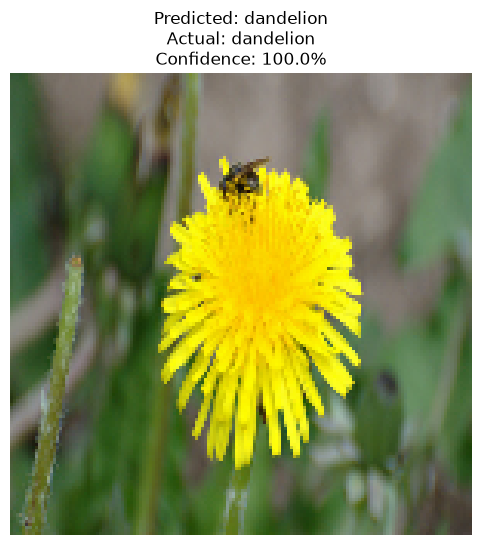

In [31]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

correct_image = None
correct_label = None
correct_prediction = None
correct_confidence = None

# Resize images before batching so all shapes match
resized_test_ds = ds_test.map(
    lambda image, label: (
        tf.image.resize(image, IMG_SIZE),
        label
    )
).batch(16)

for raw_images, raw_labels in resized_test_ds:

    # VGG16 preprocessing
    processed_images = preprocess_input(
        tf.cast(raw_images, tf.float32)
    )

    probabilities = model.predict(
        processed_images, verbose=0
    )

    predicted_indices = np.argmax(probabilities, axis=1)
    actual_indices = raw_labels.numpy().astype(int)

    # Find correctly classified images
    matches = np.where(
        predicted_indices == actual_indices
    )[0]

    if len(matches) > 0:
        i = matches[0]

        correct_image = raw_images[i].numpy().astype("uint8")
        correct_label = actual_indices[i]
        correct_prediction = predicted_indices[i]
        correct_confidence = (
            probabilities[i][correct_prediction] * 100
        )
        break

if correct_image is not None:
    plt.figure(figsize=(6, 6))
    plt.imshow(correct_image)
    plt.title(
        f"Predicted: {class_names[correct_prediction]}\n"
        f"Actual: {class_names[correct_label]}\n"
        f"Confidence: {correct_confidence:.1f}%"
    )
    plt.axis("off")
    plt.show()
else:
    print("No correctly classified image was found.")

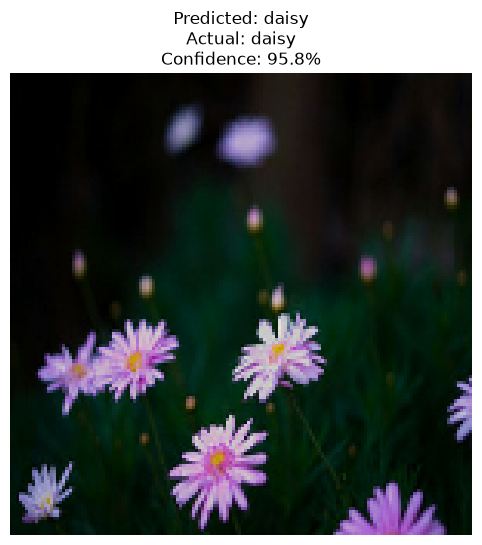

In [30]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import random

# Resize images before batching
resized_test_ds = ds_test.map(
    lambda image, label: (
        tf.image.resize(image, IMG_SIZE),
        label
    )
).batch(16)

# Collect one batch and choose a random image
images, labels = next(iter(resized_test_ds))
i = random.randrange(len(images))

# Preprocess the selected image
selected_image = images[i:i+1]
processed_image = preprocess_input(
    tf.cast(selected_image, tf.float32)
)

# Predict flower class
probabilities = model.predict(processed_image, verbose=0)[0]
predicted_index = int(np.argmax(probabilities))
actual_index = int(labels[i].numpy())

# Display prediction
plt.figure(figsize=(6, 6))
plt.imshow(images[i].numpy().astype("uint8"))
plt.title(
    f"Predicted: {class_names[predicted_index]}\n"
    f"Actual: {class_names[actual_index]}\n"
    f"Confidence: {probabilities[predicted_index] * 100:.1f}%"
)
plt.axis("off")
plt.show()